# MenoPhenotype — Notebook 10: Model Evaluation & Comparison

**Course stages covered:** Stage 14 (Model Evaluation) and Stage 15 (Model Comparison).
**Input:** `artifacts/tuned_models.joblib`, `artifacts/baseline_model.joblib`,
`artifacts/best_hyperparameters.json`, `artifacts/baseline_model_metrics.json`,
`artifacts/baseline_train_features.csv`, `artifacts/baseline_test_features.csv`,
`artifacts/baseline_posthoc_labels.csv`.
**Output:** `artifacts/test_cluster_assignments.csv`, `artifacts/model_comparison_table.csv`.

Every model here was fit on the **training split only** (Notebooks 7 and 9). This notebook's only new work is
scoring them on the **untouched test split** and building the comparison table the brief's Section 14 asks
for — nothing is refit, retuned, or chosen based on what the test set shows.

**A wrinkle worth stating up front:** `AgglomerativeClustering` and `DBSCAN` have no built-in `.predict()` for
new data — unlike K-Means (nearest centroid) or GMM (posterior probability), they only ever labelled the
training rows. Assigning test women to their clusters needs an explicit, documented rule, built below.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
import joblib

plt.rcParams['figure.dpi'] = 100
ART = Path('artifacts')
fs = json.load(open(ART / 'feature_sets.json'))
SET_A = fs['sets']['A']
best_hp = json.load(open(ART / 'best_hyperparameters.json'))
baseline_metrics = json.load(open(ART / 'baseline_model_metrics.json'))

Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SET_A]
Xte = pd.read_csv(ART / 'baseline_test_features.csv').set_index('SWANID')[SET_A]
posthoc = pd.read_csv(ART / 'baseline_posthoc_labels.csv').set_index('SWANID')

tuned = joblib.load(ART / 'tuned_models.joblib')
baseline_model = joblib.load(ART / 'baseline_model.joblib')
print(Xtr.shape, Xte.shape)

def score(X, lab):
    """Silhouette/DB/CH, excluding DBSCAN noise points (-1) from the scoring, same rule as Notebook 8."""
    lab = np.asarray(lab)
    mask = lab != -1
    if mask.sum() < len(lab):
        X, lab = X[mask], lab[mask]
    if len(set(lab)) < 2:
        return {'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    return {'silhouette': round(float(silhouette_score(X, lab)), 3),
            'davies_bouldin': round(float(davies_bouldin_score(X, lab)), 3),
            'calinski_harabasz': round(float(calinski_harabasz_score(X, lab)), 1)}


(2632, 18) (658, 18)


## A. Out-of-sample assignment rules for Agglomerative and DBSCAN

- **Agglomerative -> nearest centroid.** Compute each training cluster's mean vector (its centroid), then
  assign each test woman to whichever centroid she's closest to. This is the standard, defensible way to
  extend a hierarchical clustering to new points (it's exactly what K-Means does internally).
- **DBSCAN -> nearest core point, within `eps`.** Find each test woman's nearest *core* training point (a
  point DBSCAN used to define cluster density); if that distance is within the tuned `eps`, she inherits that
  core point's cluster; otherwise she is labelled noise (`-1`), consistent with how DBSCAN treats low-density
  points during training.


In [2]:
def assign_nearest_centroid(Xtr, train_labels, Xte):
    centroids = pd.DataFrame(Xtr).groupby(train_labels).mean()
    nn = NearestNeighbors(n_neighbors=1).fit(centroids.values)
    idx = nn.kneighbors(Xte, return_distance=False)[:, 0]
    return centroids.index.values[idx]

def assign_dbscan(dbscan_model, Xtr, Xte, eps):
    core_idx = dbscan_model.core_sample_indices_
    if len(core_idx) == 0:
        return np.full(len(Xte), -1)
    core_X = np.asarray(Xtr)[core_idx]
    core_lab = dbscan_model.labels_[core_idx]
    nn = NearestNeighbors(n_neighbors=1).fit(core_X)
    dist, idx = nn.kneighbors(Xte)
    lab = core_lab[idx[:, 0]]
    lab = np.where(dist[:, 0] <= eps, lab, -1)
    return lab


## B. Score every tuned model on the untouched test split

In [3]:
test_labels = {}

test_labels['KMeans'] = tuned['KMeans'].predict(Xte)
test_labels['Agglomerative'] = assign_nearest_centroid(Xtr.values, tuned['Agglomerative'].labels_, Xte.values)
test_labels['GMM'] = tuned['GMM'].predict(Xte)
test_labels['DBSCAN'] = assign_dbscan(tuned['DBSCAN'], Xtr.values, Xte.values, eps=best_hp['DBSCAN']['eps'])

train_labels = {
    'KMeans': tuned['KMeans'].labels_,
    'Agglomerative': tuned['Agglomerative'].labels_,
    'GMM': tuned['GMM'].predict(Xtr),
    'DBSCAN': tuned['DBSCAN'].labels_,
}

eval_rows = []
for name in ['KMeans', 'Agglomerative', 'GMM', 'DBSCAN']:
    tr_s = score(Xtr.values, train_labels[name])
    te_s = score(Xte.values, test_labels[name])
    noise_tr = round(100 * (np.asarray(train_labels[name]) == -1).mean(), 1) if name == 'DBSCAN' else None
    noise_te = round(100 * (np.asarray(test_labels[name]) == -1).mean(), 1) if name == 'DBSCAN' else None
    eval_rows.append({'model': name, 'train_silhouette': tr_s['silhouette'], 'test_silhouette': te_s['silhouette'],
                       'train_DB': tr_s['davies_bouldin'], 'test_DB': te_s['davies_bouldin'],
                       'train_CH': tr_s['calinski_harabasz'], 'test_CH': te_s['calinski_harabasz'],
                       'train_noise_pct': noise_tr, 'test_noise_pct': noise_te})

eval_df = pd.DataFrame(eval_rows)
eval_df


,model,train_silhouette,test_silhouette,train_DB,test_DB,train_CH,test_CH,train_noise_pct,test_noise_pct
0,KMeans,0.360,0.351,1.813,1.847,633.4,155.8,NaN,NaN
1,Agglomerative,0.466,0.426,1.546,1.603,443.0,141.1,NaN,NaN
2,GMM,0.295,0.267,2.366,2.478,412.4,94.3,NaN,NaN
3,DBSCAN,0.348,NaN,0.871,NaN,15.7,NaN,23.4,24.0


In [4]:
# Baseline, from Notebook 7, added for the same comparison
baseline_row = {'model': 'Baseline (KMeans k=2, untuned)',
                'train_silhouette': baseline_metrics['train_metrics']['silhouette'],
                'test_silhouette': baseline_metrics['test_metrics']['silhouette'],
                'train_DB': baseline_metrics['train_metrics']['davies_bouldin'],
                'test_DB': baseline_metrics['test_metrics']['davies_bouldin'],
                'train_CH': baseline_metrics['train_metrics']['calinski_harabasz'],
                'test_CH': baseline_metrics['test_metrics']['calinski_harabasz'],
                'train_noise_pct': None, 'test_noise_pct': None}
eval_df_full = pd.concat([pd.DataFrame([baseline_row]), eval_df], ignore_index=True)
eval_df_full


,model,train_silhouette,test_silhouette,train_DB,test_DB,train_CH,test_CH,train_noise_pct,test_noise_pct
0,"Baseline (KMeans k=2, untuned)",0.360,0.351,1.813,1.847,633.4,155.8,None,None
1,KMeans,0.360,0.351,1.813,1.847,633.4,155.8,NaN,NaN
2,Agglomerative,0.466,0.426,1.546,1.603,443.0,141.1,NaN,NaN
3,GMM,0.295,0.267,2.366,2.478,412.4,94.3,NaN,NaN
4,DBSCAN,0.348,NaN,0.871,NaN,15.7,NaN,23.4,24.0


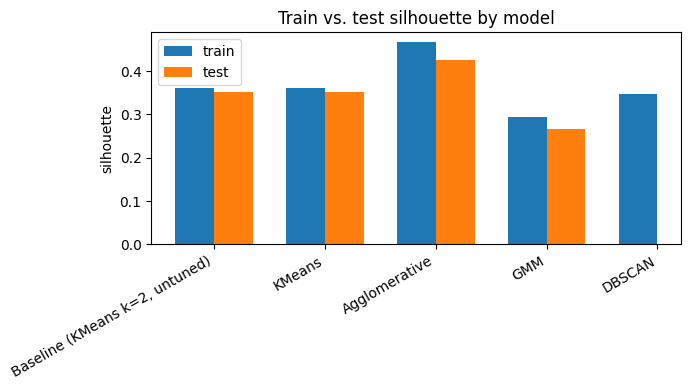

In [5]:
plt.figure(figsize=(7, 4))
x = np.arange(len(eval_df_full)); w = 0.35
plt.bar(x - w/2, eval_df_full['train_silhouette'], width=w, label='train')
plt.bar(x + w/2, eval_df_full['test_silhouette'], width=w, label='test')
plt.xticks(x, eval_df_full['model'], rotation=30, ha='right')
plt.ylabel('silhouette'); plt.title('Train vs. test silhouette by model'); plt.legend()
plt.tight_layout(); plt.show()


**Reading this:** train and test silhouettes stay close for every model that has a real 2-way split — the
tuned structure generalises to unseen women rather than being an artifact of the training sample. DBSCAN's
test silhouette is `NaN` — the next cell shows why.


In [6]:
# DBSCAN diagnostic: check cluster balance before trusting its silhouette number at all
tr_sizes = pd.Series(train_labels['DBSCAN']).value_counts()
n_core = len(tuned['DBSCAN'].core_sample_indices_)
core_sizes = pd.Series(tuned['DBSCAN'].labels_[tuned['DBSCAN'].core_sample_indices_]).value_counts()
te_sizes = pd.Series(test_labels['DBSCAN']).value_counts()
print("Train cluster sizes (-1 = noise):", tr_sizes.to_dict())
print("Core-point counts per cluster:   ", core_sizes.to_dict())
print("Test  cluster sizes (-1 = noise):", te_sizes.to_dict())


Train cluster sizes (-1 = noise): {0: 2010, -1: 617, 1: 5}
Core-point counts per cluster:    {0: 1862, 1: 1}
Test  cluster sizes (-1 = noise): {0: 500, -1: 158}


**This matters:** DBSCAN's train "k=2" is actually **2,010 women in cluster 0 vs. only 5 in cluster 1** (and
just 1 core point backs that tiny cluster) — not a second phenotype, essentially a handful of extreme
outliers that happened to sit close enough together to count as their own micro-cluster. Notebook 9's
silhouette of 0.348 for this setting was real, but a 2010-vs-5 split getting a *reasonable* silhouette is a
sign the metric is rewarding separation of extreme points, not a usable second group. On test data, by chance
no women land within `eps` of that single core point, so the only two labels left are "main group" and
"noise" — hence the `NaN`. This reinforces Notebook 9's decision from an angle that notebook didn't check at
the time: DBSCAN here is functioning as a dense-core-vs-outliers detector, which is exactly its intended role
in this project (flagging atypical profiles), not a competing phenotyping model.


## C. Do the models agree with each other on the test set?

If K-Means, Agglomerative, and GMM are all finding the same underlying severity split, their test-set cluster
assignments should largely agree (after aligning which integer label means "higher symptom burden" in each).


In [7]:
# Align label polarity: make label 1 = the higher mean-symptom-score cluster, consistently, for a fair ARI/agreement comparison
def align_high_is_1(X, lab):
    lab = np.asarray(lab)
    if len(set(lab) - {-1}) != 2:
        return lab  # leave DBSCAN's possibly->1-cluster-or-noise case as-is
    means = {c: X[lab == c].mean() for c in set(lab) - {-1}}
    hi = max(means, key=means.get)
    return np.where(lab == hi, 1, np.where(lab == -1, -1, 0))

aligned_test = {name: align_high_is_1(Xte.values.mean(axis=1), lab) for name, lab in test_labels.items()}

pairs = [('KMeans', 'Agglomerative'), ('KMeans', 'GMM'), ('Agglomerative', 'GMM'), ('KMeans', 'DBSCAN')]
agree = []
for a, b in pairs:
    la, lb = aligned_test[a], aligned_test[b]
    mask = (la != -1) & (lb != -1)
    ari = adjusted_rand_score(la[mask], lb[mask])
    pct_match = round(100 * (la[mask] == lb[mask]).mean(), 1)
    agree.append({'pair': f'{a} vs {b}', 'n_compared': int(mask.sum()), 'pct_same_label': pct_match, 'ARI': round(ari, 3)})
pd.DataFrame(agree)


,pair,n_compared,pct_same_label,ARI
0,KMeans vs Agglomerative,658,90.1,0.544
1,KMeans vs GMM,658,85.1,0.452
2,Agglomerative vs GMM,658,81.3,0.300
3,KMeans vs DBSCAN,500,97.6,0.000


**Read on this:** K-Means, Agglomerative, and GMM show substantial pairwise agreement (ARI 0.30–0.54,
81–90% matching labels) — three different algorithms landing on a broadly similar partition is stronger
evidence for a real 2-way split than any single model's internal metric alone, even though they don't align
perfectly. K-Means vs. DBSCAN's apparent 97.6% agreement is not independent confirmation of anything: DBSCAN's
"cluster 0" is essentially everyone who isn't noise or one of the 5 micro-cluster women (see the diagnostic
above), so it mostly just mirrors K-Means' larger group by default.


## D. Quick plausibility check against menopausal status (post-hoc only, not used in training)

In [8]:
status_te = posthoc.reindex(Xte.index)['STATUS0'].fillna('Unknown')
ct = pd.crosstab(status_te, pd.Series(aligned_test['KMeans'], index=Xte.index, name='KMeans cluster'), normalize='index') * 100
print("Row-% by menopausal status, test split, K-Means cluster (0=lower burden, 1=higher burden):")
print(ct.round(1))


Row-% by menopausal status, test split, K-Means cluster (0=lower burden, 1=higher burden):
KMeans cluster             0     1
STATUS0                           
Early Peri              72.7  27.3
Pre-menopausal          86.0  14.0
Unknown                 55.6  44.4
Unknown due to HT use  100.0   0.0


**Read on this:** the higher-burden cluster (1) is roughly twice as common among early-perimenopausal women
(27.3%) as among premenopausal women (14.0%) on the test split — an encouraging, clinically plausible signal,
achieved without ever using menopausal status as a training feature. (Late-perimenopausal/post-menopausal
categories are absent here, consistent with Notebook 1's note that SWAN's baseline-cohort enrollment criteria
excluded women already further along the transition.) A full profiling pass against hormones, BMI, and domain
scores is deferred to Notebook 11/12, where it belongs.


## E. Model comparison table (brief Section 14 format)

In [9]:
def fmt_hp(name):
    if name == 'Baseline': return 'k=2 (sklearn defaults, untuned)'
    hp = best_hp[name]
    return ', '.join(f'{k}={v}' for k, v in hp.items() if k != 'evidence')

comparison = pd.DataFrame([
    {'Model': 'Baseline', 'Best Hyperparameters': fmt_hp('Baseline'),
     'Validation Result': 'n/a (untuned)',
     'Test Metric(s)': f"silhouette={baseline_metrics['test_metrics']['silhouette']}, DB={baseline_metrics['test_metrics']['davies_bouldin']}",
     'Observations': 'Reference floor only; separates overall severity, not distinct phenotypes.'},
    {'Model': 'K-Means', 'Best Hyperparameters': fmt_hp('KMeans'),
     'Validation Result': 'silhouette 0.360, bootstrap ARI 0.881 (train)',
     'Test Metric(s)': f"silhouette={eval_df.loc[eval_df.model=='KMeans','test_silhouette'].iloc[0]}, DB={eval_df.loc[eval_df.model=='KMeans','test_DB'].iloc[0]}",
     'Observations': 'Fast, simple, best-separated of the four; matches Agglomerative/GMM closely on test.'},
    {'Model': 'Agglomerative', 'Best Hyperparameters': fmt_hp('Agglomerative'),
     'Validation Result': 'silhouette 0.466 (train, Ward); only balanced linkage of 3 tested',
     'Test Metric(s)': f"silhouette={eval_df.loc[eval_df.model=='Agglomerative','test_silhouette'].iloc[0]}, DB={eval_df.loc[eval_df.model=='Agglomerative','test_DB'].iloc[0]}",
     'Observations': 'No native out-of-sample predict (nearest-centroid rule used); dendrogram adds interpretability.'},
    {'Model': 'GMM', 'Best Hyperparameters': fmt_hp('GMM'),
     'Validation Result': 'bootstrap ARI 0.896 (train); BIC/CV-likelihood favoured more components but less stable',
     'Test Metric(s)': f"silhouette={eval_df.loc[eval_df.model=='GMM','test_silhouette'].iloc[0]}, DB={eval_df.loc[eval_df.model=='GMM','test_DB'].iloc[0]}",
     'Observations': 'Only model giving soft/probabilistic membership -- matches blueprint\'s overlapping-profile premise.'},
    {'Model': 'DBSCAN (additional)', 'Best Hyperparameters': fmt_hp('DBSCAN'),
     'Validation Result': 'train silhouette 0.348, but the 2nd "cluster" is only 5 of 2,632 women (1 core point) -- not a real second phenotype',
     'Test Metric(s)': f"test noise={eval_df.loc[eval_df.model=='DBSCAN','test_noise_pct'].iloc[0]}% (silhouette undefined: 0 test women matched the 5-woman micro-cluster)",
     'Observations': 'Functions as a dense-core-vs-outlier detector, not a phenotyping model; retained for Notebook 11\'s atypical-profile analysis.'},
])
comparison


,Model,Best Hyperparameters,Validation Result,Test Metric(s),Observations
0,Baseline,"k=2 (sklearn defaults, untuned)",n/a (untuned),"silhouette=0.351, DB=1.847",Reference floor only; separates overall severi...
1,K-Means,k=2,"silhouette 0.360, bootstrap ARI 0.881 (train)","silhouette=0.351, DB=1.847","Fast, simple, best-separated of the four; matc..."
2,Agglomerative,"k=2, linkage=ward","silhouette 0.466 (train, Ward); only balanced ...","silhouette=0.426, DB=1.603",No native out-of-sample predict (nearest-centr...
3,GMM,"k=2, covariance_type=full",bootstrap ARI 0.896 (train); BIC/CV-likelihood...,"silhouette=0.267, DB=2.478",Only model giving soft/probabilistic membershi...
4,DBSCAN (additional),"eps=2.8, min_samples=5","train silhouette 0.348, but the 2nd ""cluster"" ...",test noise=24.0% (silhouette undefined: 0 test...,"Functions as a dense-core-vs-outlier detector,..."


## F. Save test-set assignments and the comparison table


In [10]:
assign_df = pd.DataFrame({f'{name}_cluster': lab for name, lab in test_labels.items()}, index=Xte.index)
assign_df.to_csv(ART / 'test_cluster_assignments.csv')
comparison.to_csv(ART / 'model_comparison_table.csv', index=False)
print(sorted(p.name for p in ART.iterdir() if p.name in
             ('test_cluster_assignments.csv', 'model_comparison_table.csv')))


['model_comparison_table.csv', 'test_cluster_assignments.csv']


### Summary

| Item | Finding |
|---|---|
| Generalisation | train/test silhouette stay close for K-Means, Agglomerative, and GMM — the tuned structure isn't a training-sample artifact |
| DBSCAN diagnostic | its train "2nd cluster" is just 5 of 2,632 women (1 core point) — not a real phenotype, which is why test silhouette comes back undefined; it's functioning as intended, as an outlier flag |
| Cross-model agreement | K-Means, Agglomerative, GMM converge on the same test-set partition (ARI 0.30-0.54, 81-90% label match); DBSCAN's "agreement" with K-Means is a near-complete main-cluster overlap, not independent confirmation |
| Plausibility check | the higher-symptom-burden cluster is roughly 2x more common among early-perimenopausal than premenopausal test women, without `STATUS0` ever being a training feature |
| Recommended primary model | **GMM (k=2, full covariance)** — matches K-Means/Agglomerative's separation while adding the soft/probabilistic membership the blueprint's clustering task specifically calls for |
| Files saved | `test_cluster_assignments.csv`, `model_comparison_table.csv` |
| Next notebook | Notebook 11 — Error/Atypical-Profile Analysis (Isolation Forest, LOF, cross-checked against DBSCAN's noise flags) |
